
# Residential Electricity Load Profile Modeling

## Grid-Connected Solar PV–Wind–Battery Hybrid Microgrid

**Study Location:** Saint-Brieuc, Brittany, France  
**Simulation Software:** HOMER Pro 3.18.5  
**Programming Language:** Python  
**Simulation Year:** 2026  
**Number of Households:** 100

### Project Objective

This notebook develops a customized 8,760-hour electricity demand profile for a hypothetical residential community of 100 households in Saint-Brieuc, France.

The model considers general household electricity consumption, heat pump electricity demand, and conventional electric space heating.

The resulting hourly load profile will be validated against an annual electricity consumption target of 655,000 kWh and exported for use in HOMER Pro.

### Household Heating Distribution

- 45 households with heat pumps (45%)
- 35 households with conventional electric heating (35%)
- 20 households with non-electric space heating (20%)

**Note:** Electricity demand assumptions are illustrative and do not represent measured consumption data.
  

In [2]:

# Import required Python libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project configuration
YEAR = 2026
TOTAL_HOUSEHOLDS = 100

HEAT_PUMP_HOUSEHOLDS = 45
ELECTRIC_HEATING_HOUSEHOLDS = 35
NON_ELECTRIC_HEATING_HOUSEHOLDS = 20

ANNUAL_ENERGY_TARGET = 655_000  # kWh/year

# Create an hourly datetime index
time_index = pd.date_range(
    start=f"{YEAR}-01-01 00:00",
    end=f"{YEAR + 1}-01-01 00:00",
    freq="h",
    inclusive="left"
)

print("Total households:", TOTAL_HOUSEHOLDS)
print("Simulation year:", YEAR)
print("Total hourly time steps:", len(time_index))
print("Annual electricity target:", ANNUAL_ENERGY_TARGET, "kWh")

# Validate initial assumptions
assert (
    HEAT_PUMP_HOUSEHOLDS
    + ELECTRIC_HEATING_HOUSEHOLDS
    + NON_ELECTRIC_HEATING_HOUSEHOLDS
    == TOTAL_HOUSEHOLDS
)

assert len(time_index) == 8760


Total households: 100
Simulation year: 2026
Total hourly time steps: 8760
Annual electricity target: 655000 kWh



## 2. General Household Electricity Demand

### 2.1 Objective

This section models hourly electricity consumption for
general household appliances across 100 households
in Saint-Brieuc, France.

The model includes lighting, refrigeration, cooking,
washing machines, televisions, computers, and other
household electrical appliances.

### 2.2 Assumptions

- Total households: 100
- Annual electricity per household: 3,500 kWh
- Total annual appliance demand: 350,000 kWh
- Simulation resolution: 1 hour

### 2.3 Methodology

A normalized 24-hour residential consumption pattern
is used to distribute annual electricity demand
across 8,760 hourly intervals.

Higher consumption is assumed during morning and
evening hours, while nighttime consumption is lower.

The profile is illustrative and will be refined to
include seasonal and weekday/weekend variations.


In [4]:

# STEP 2: General household electricity demand

# Define hourly appliance consumption weights
hourly_appliance_weights = np.array([
    0.45, 0.40, 0.35, 0.35, 0.40, 0.55,
    0.80, 1.20, 1.30, 1.00, 0.85, 0.90,
    1.10, 1.05, 0.90, 0.95, 1.10, 1.45,
    1.80, 2.00, 1.85, 1.50, 1.00, 0.65
])

# Annual appliance electricity target
ANNUAL_APPLIANCE_ENERGY = 350_000

# Extract hour of day
hours = time_index.hour

# Generate hourly appliance demand weights
appliance_profile = hourly_appliance_weights[hours]

# Normalize to annual electricity consumption
appliance_load_kw = (
    appliance_profile
    / appliance_profile.sum()
    * ANNUAL_APPLIANCE_ENERGY
)

# Create DataFrame
load_df = pd.DataFrame({
    "Datetime": time_index,
    "Appliance_Load_kW": appliance_load_kw
})

# Validate electricity consumption
calculated_energy = load_df["Appliance_Load_kW"].sum()

print("Annual appliance demand:",
      round(calculated_energy, 2), "kWh")

print("Average appliance load:",
      round(load_df["Appliance_Load_kW"].mean(), 2), "kW")

print("Peak appliance load:",
      round(load_df["Appliance_Load_kW"].max(), 2), "kW")

print("Total hourly records:", len(load_df))

assert np.isclose(
    calculated_energy,
    ANNUAL_APPLIANCE_ENERGY
)

load_df.head()


Annual appliance demand: 350000.0 kWh
Average appliance load: 39.95 kW
Peak appliance load: 80.24 kW
Total hourly records: 8760


,Datetime,Appliance_Load_kW
0,2026-01-01 00:00:00,18.054680
1,2026-01-01 01:00:00,16.048604
2,2026-01-01 02:00:00,14.042529
3,2026-01-01 03:00:00,14.042529
4,2026-01-01 04:00:00,16.048604


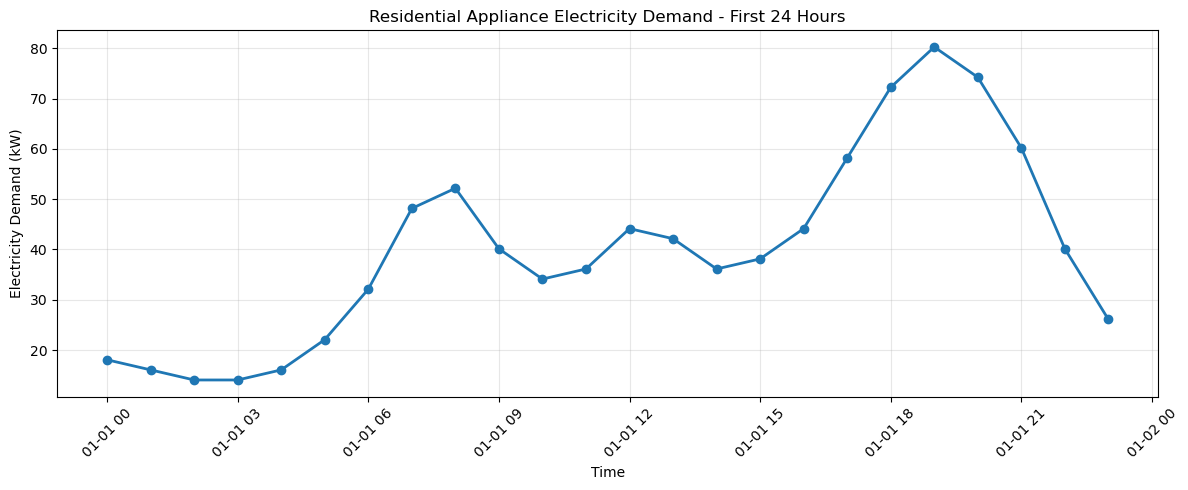

In [5]:

# Visualize the first 24 hours of appliance demand

daily_load = load_df.iloc[:24]

plt.figure(figsize=(12, 5))

plt.plot(
    daily_load["Datetime"],
    daily_load["Appliance_Load_kW"],
    marker="o",
    linewidth=2
)

plt.title("Residential Appliance Electricity Demand - First 24 Hours")
plt.xlabel("Time")
plt.ylabel("Electricity Demand (kW)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## 3. Heat Pump Electricity Demand Modeling

### 3.1 Objective

This section develops an hourly electricity demand profile
for 45 households equipped with heat pumps in Saint-Brieuc,
Brittany, France.

The model represents seasonal variations in space-heating
electricity demand, with higher consumption during winter
and lower consumption during summer.

### 3.2 Modeling Assumptions

- Heat pump households: 45
- Annual electricity per household: 2,500 kWh
- Total annual heat pump electricity: 112,500 kWh
- Simulation year: 2026
- Time resolution: 1 hour

### 3.3 Methodology

Monthly heating weights and hourly demand factors are
combined to generate an annual electricity demand profile.

The resulting hourly values are normalized to match the
annual heat pump electricity consumption target.

This is an illustrative load model. Future improvements
may incorporate measured outdoor temperatures, heating
degree hours, and heat pump coefficient of performance (COP).


In [8]:

# STEP 3: Heat pump electricity demand modeling

# Annual heat pump electricity target (kWh)
ANNUAL_HEAT_PUMP_ENERGY = 112_500

# Monthly heating demand weights (January to December)
monthly_hp_weights = np.array([
    1.80, 1.60, 1.30, 0.90,
    0.50, 0.15, 0.05, 0.05,
    0.30, 0.80, 1.30, 1.70
])

# Hourly heat pump demand weights (00:00 to 23:00)
hourly_hp_weights = np.array([
    1.10, 1.10, 1.05, 1.05, 1.10, 1.20,
    1.40, 1.50, 1.30, 1.10, 0.95, 0.90,
    0.85, 0.85, 0.90, 1.00, 1.20, 1.45,
    1.60, 1.65, 1.55, 1.40, 1.25, 1.15
])

# Extract month and hour from time index
months = time_index.month
hours = time_index.hour

# Combine monthly and hourly demand patterns
hp_profile = (
    monthly_hp_weights[months - 1]
    * hourly_hp_weights[hours]
)

# Scale the profile to match annual electricity demand
heat_pump_load_kw = (
    hp_profile
    / hp_profile.sum()
    * ANNUAL_HEAT_PUMP_ENERGY
)

# Add heat pump electricity to the existing DataFrame
load_df["Heat_Pump_Load_kW"] = heat_pump_load_kw

# Calculate annual electricity consumption
calculated_hp_energy = load_df["Heat_Pump_Load_kW"].sum()

# Display results
print("Annual heat pump electricity:",
      round(calculated_hp_energy, 2), "kWh")

print("Average heat pump load:",
      round(load_df["Heat_Pump_Load_kW"].mean(), 2), "kW")

print("Peak heat pump load:",
      round(load_df["Heat_Pump_Load_kW"].max(), 2), "kW")

print("Total hourly records:", len(load_df))

# Validate the annual electricity target
assert np.isclose(
    calculated_hp_energy,
    ANNUAL_HEAT_PUMP_ENERGY
)

load_df.head()


Annual heat pump electricity: 112500.0 kWh
Average heat pump load: 12.84 kW
Peak heat pump load: 36.91 kW
Total hourly records: 8760


,Datetime,Appliance_Load_kW,Heat_Pump_Load_kW
0,2026-01-01 00:00:00,18.054680,24.608093
1,2026-01-01 01:00:00,16.048604,24.608093
2,2026-01-01 02:00:00,14.042529,23.489544
3,2026-01-01 03:00:00,14.042529,23.489544
4,2026-01-01 04:00:00,16.048604,24.608093


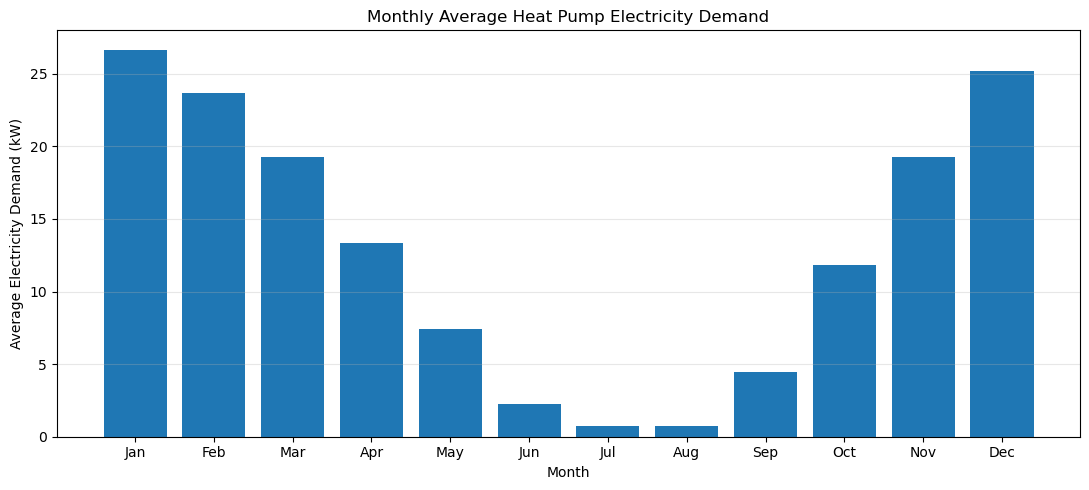

In [9]:

# STEP 3.6: Visualize heat pump electricity demand

# Create a monthly average heat pump load profile
monthly_hp_load = (
    load_df
    .set_index("Datetime")["Heat_Pump_Load_kW"]
    .resample("MS")
    .mean()
)

plt.figure(figsize=(11, 5))

plt.bar(
    monthly_hp_load.index.strftime("%b"),
    monthly_hp_load.values
)

plt.title("Monthly Average Heat Pump Electricity Demand")
plt.xlabel("Month")
plt.ylabel("Average Electricity Demand (kW)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



## 4. Conventional Electric Heating Demand Modeling

### 4.1 Objective

This section develops an hourly electricity demand profile
for 35 households using conventional electric space heating
in Saint-Brieuc, Brittany, France.

The model accounts for seasonal and hourly heating
demand variations, with higher electricity consumption
during winter and lower consumption during summer.

### 4.2 Modeling Assumptions

- Conventional electric-heating households: 35
- Annual heating electricity per household: 5,500 kWh
- Total annual electric-heating demand: 192,500 kWh
- Simulation year: 2026
- Time resolution: 1 hour

### 4.3 Methodology

Monthly seasonal heating weights are combined with
hourly demand weights to generate an 8,760-hour
electricity consumption profile.

The resulting profile is normalized to match the
annual electric-heating demand target.

The model uses illustrative heating assumptions
rather than measured temperature data.


In [10]:

# STEP 4: Conventional electric heating demand

ANNUAL_ELECTRIC_HEATING_ENERGY = 192_500  # kWh/year

# Monthly heating demand weights: January to December
monthly_electric_heating_weights = np.array([
    2.00, 1.80, 1.40, 0.80,
    0.30, 0.05, 0.01, 0.01,
    0.15, 0.70, 1.40, 1.90
])

# Hourly heating demand weights: 00:00 to 23:00
hourly_electric_heating_weights = np.array([
    1.00, 0.90, 0.85, 0.85, 0.90, 1.10,
    1.50, 1.70, 1.50, 1.10, 0.90, 0.80,
    0.75, 0.75, 0.80, 0.90, 1.20, 1.60,
    1.90, 2.00, 1.80, 1.50, 1.30, 1.10
])

# Extract month and hour
months = time_index.month
hours = time_index.hour

# Combine seasonal and hourly demand patterns
electric_heating_profile = (
    monthly_electric_heating_weights[months - 1]
    * hourly_electric_heating_weights[hours]
)

# Normalize to annual electricity consumption
electric_heating_load_kw = (
    electric_heating_profile
    / electric_heating_profile.sum()
    * ANNUAL_ELECTRIC_HEATING_ENERGY
)

# Add conventional electric heating to DataFrame
load_df["Electric_Heating_Load_kW"] = electric_heating_load_kw

# Validate annual electricity consumption
calculated_heating_energy = load_df[
    "Electric_Heating_Load_kW"
].sum()

print(
    "Annual electric heating demand:",
    round(calculated_heating_energy, 2),
    "kWh"
)

print(
    "Average electric heating load:",
    round(load_df["Electric_Heating_Load_kW"].mean(), 2),
    "kW"
)

print(
    "Peak electric heating load:",
    round(load_df["Electric_Heating_Load_kW"].max(), 2),
    "kW"
)

print("Total hourly records:", len(load_df))

assert np.isclose(
    calculated_heating_energy,
    ANNUAL_ELECTRIC_HEATING_ENERGY
)

load_df.head()


Annual electric heating demand: 192500.0 kWh
Average electric heating load: 21.97 kW
Peak electric heating load: 84.28 kW
Total hourly records: 8760


,Datetime,Appliance_Load_kW,Heat_Pump_Load_kW,Electric_Heating_Load_kW
0,2026-01-01 00:00:00,18.054680,24.608093,42.141977
1,2026-01-01 01:00:00,16.048604,24.608093,37.927779
2,2026-01-01 02:00:00,14.042529,23.489544,35.820681
3,2026-01-01 03:00:00,14.042529,23.489544,35.820681
4,2026-01-01 04:00:00,16.048604,24.608093,37.927779


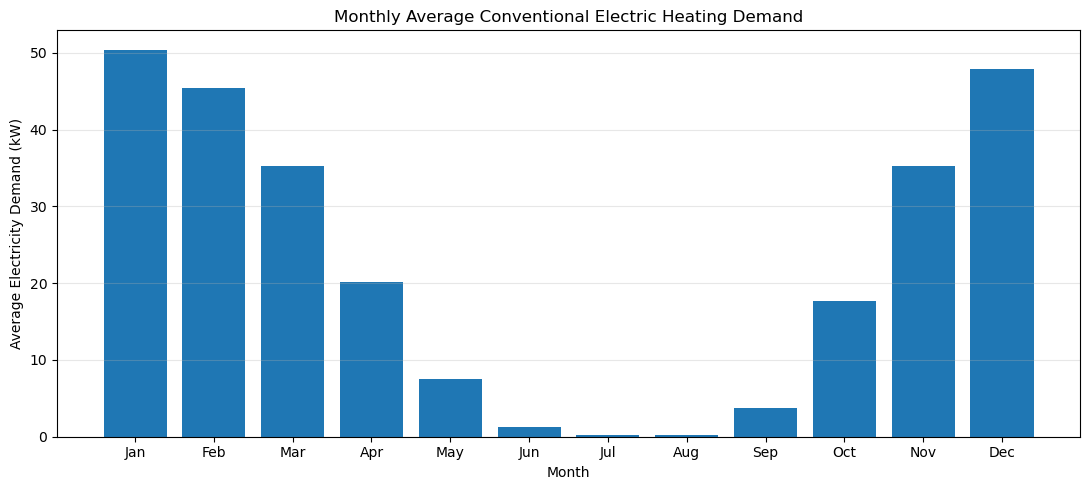

In [11]:

# STEP 4.6: Visualize monthly electric heating demand

monthly_electric_heating = (
    load_df
    .set_index("Datetime")["Electric_Heating_Load_kW"]
    .resample("MS")
    .mean()
)

plt.figure(figsize=(11, 5))

plt.bar(
    monthly_electric_heating.index.strftime("%b"),
    monthly_electric_heating.values
)

plt.title("Monthly Average Conventional Electric Heating Demand")
plt.xlabel("Month")
plt.ylabel("Average Electricity Demand (kW)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



## 5. Combined Residential Electricity Load Profile

### 5.1 Objective

This section combines the three electricity demand components
into a single hourly electricity load profile for the
100-household residential community in Saint-Brieuc, France.

The components include:

1. General household appliance electricity demand.
2. Heat pump electricity demand.
3. Conventional electric space heating demand.

### 5.2 Methodology

The total hourly electricity demand is calculated as:

Total Load = Appliance Load + Heat Pump Load + Electric Heating Load

The resulting 8,760-hour profile is evaluated using:

- Total annual electricity consumption (kWh)
- Average daily electricity consumption (kWh/day)
- Average electrical power (kW)
- Maximum hourly electricity demand (kW)
- Load factor
- Monthly electricity consumption (kWh)

The model is validated against the annual electricity
consumption target of 655,000 kWh.

All electricity demand values are based on illustrative
engineering assumptions rather than measured household data.


In [12]:

# STEP 5.3: Combine all electricity demand components

# Calculate total hourly electricity demand
load_df["Total_Load_kW"] = (
    load_df["Appliance_Load_kW"]
    + load_df["Heat_Pump_Load_kW"]
    + load_df["Electric_Heating_Load_kW"]
)

# Calculate electricity demand statistics
annual_energy_kwh = load_df["Total_Load_kW"].sum()

average_daily_energy = annual_energy_kwh / 365

average_load_kw = load_df["Total_Load_kW"].mean()

peak_load_kw = load_df["Total_Load_kW"].max()

load_factor = average_load_kw / peak_load_kw

# Display results
print("RESIDENTIAL ELECTRICITY LOAD SUMMARY")
print("-" * 45)

print(f"Annual electricity demand: {annual_energy_kwh:,.2f} kWh")
print(f"Average daily demand: {average_daily_energy:,.2f} kWh/day")
print(f"Average electrical power: {average_load_kw:,.2f} kW")
print(f"Peak electrical demand: {peak_load_kw:,.2f} kW")
print(f"Load factor: {load_factor:.3f}")
print(f"Hourly records: {len(load_df):,}")

# Validate annual electricity consumption
assert np.isclose(
    annual_energy_kwh,
    ANNUAL_ENERGY_TARGET
), "Annual electricity demand does not match target!"

assert len(load_df) == 8760, "Incorrect number of hourly records!"

print("\nValidation successful!")

load_df.head()


RESIDENTIAL ELECTRICITY LOAD SUMMARY
---------------------------------------------
Annual electricity demand: 655,000.00 kWh
Average daily demand: 1,794.52 kWh/day
Average electrical power: 74.77 kW
Peak electrical demand: 201.44 kW
Load factor: 0.371
Hourly records: 8,760

Validation successful!


,Datetime,Appliance_Load_kW,Heat_Pump_Load_kW,Electric_Heating_Load_kW,Total_Load_kW
0,2026-01-01 00:00:00,18.054680,24.608093,42.141977,84.804750
1,2026-01-01 01:00:00,16.048604,24.608093,37.927779,78.584477
2,2026-01-01 02:00:00,14.042529,23.489544,35.820681,73.352753
3,2026-01-01 03:00:00,14.042529,23.489544,35.820681,73.352753
4,2026-01-01 04:00:00,16.048604,24.608093,37.927779,78.584477


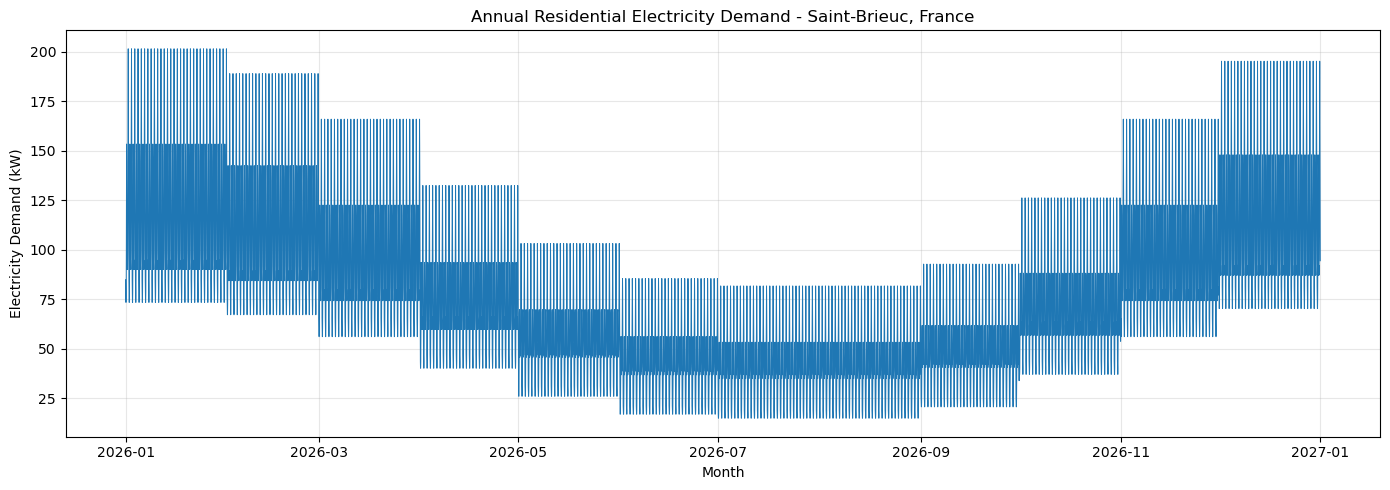

In [13]:

# STEP 5.4: Visualize annual residential electricity demand

plt.figure(figsize=(14, 5))

plt.plot(
    load_df["Datetime"],
    load_df["Total_Load_kW"],
    linewidth=0.7
)

plt.title(
    "Annual Residential Electricity Demand - Saint-Brieuc, France"
)

plt.xlabel("Month")
plt.ylabel("Electricity Demand (kW)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


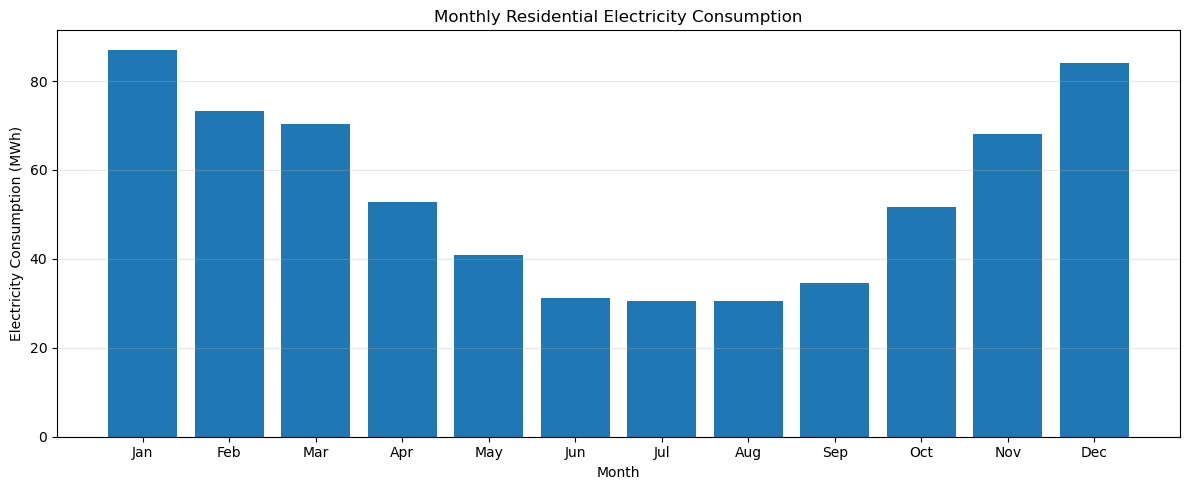

MONTHLY ELECTRICITY CONSUMPTION (MWh)
Datetime
2026-01-01    87.05
2026-02-01    73.25
2026-03-01    70.30
2026-04-01    52.88
2026-05-01    40.86
2026-06-01    31.27
2026-07-01    30.46
2026-08-01    30.46
2026-09-01    34.69
2026-10-01    51.66
2026-11-01    68.03
2026-12-01    84.08
Freq: MS, Name: Total_Load_kW, dtype: float64

Total annual electricity: 655000.0 kWh


In [14]:

# STEP 5.5: Calculate monthly electricity consumption

monthly_energy = (
    load_df
    .set_index("Datetime")["Total_Load_kW"]
    .resample("MS")
    .sum()
)

monthly_energy_mwh = monthly_energy / 1000

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_energy_mwh.index.strftime("%b"),
    monthly_energy_mwh.values
)

plt.title("Monthly Residential Electricity Consumption")
plt.xlabel("Month")
plt.ylabel("Electricity Consumption (MWh)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("MONTHLY ELECTRICITY CONSUMPTION (MWh)")
print(monthly_energy_mwh.round(2))

print(
    "\nTotal annual electricity:",
    round(monthly_energy.sum(), 2),
    "kWh"
)


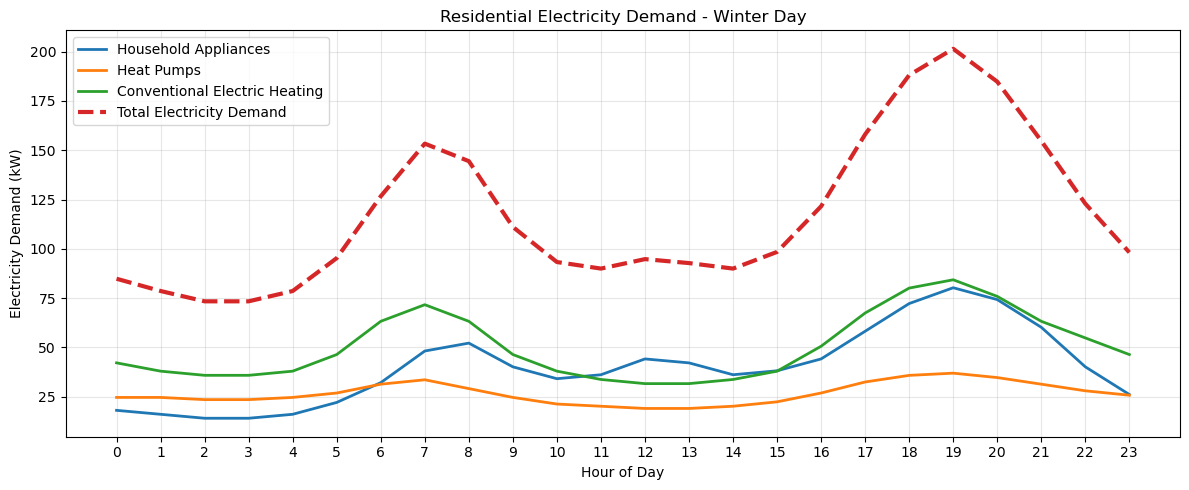

In [15]:

# STEP 5.6: Visualize a typical winter day

winter_day = load_df[
    load_df["Datetime"].dt.date
    == pd.Timestamp("2026-01-15").date()
]

plt.figure(figsize=(12, 5))

plt.plot(
    winter_day["Datetime"].dt.hour,
    winter_day["Appliance_Load_kW"],
    label="Household Appliances",
    linewidth=2
)

plt.plot(
    winter_day["Datetime"].dt.hour,
    winter_day["Heat_Pump_Load_kW"],
    label="Heat Pumps",
    linewidth=2
)

plt.plot(
    winter_day["Datetime"].dt.hour,
    winter_day["Electric_Heating_Load_kW"],
    label="Conventional Electric Heating",
    linewidth=2
)

plt.plot(
    winter_day["Datetime"].dt.hour,
    winter_day["Total_Load_kW"],
    label="Total Electricity Demand",
    linewidth=3,
    linestyle="--"
)

plt.title("Residential Electricity Demand - Winter Day")
plt.xlabel("Hour of Day")
plt.ylabel("Electricity Demand (kW)")

plt.xticks(range(0, 24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:

# STEP 5.7: Validate all electricity demand components

energy_summary = pd.DataFrame({
    "Category": [
        "Household Appliances",
        "Heat Pumps",
        "Conventional Electric Heating",
        "Total"
    ],
    "Annual_Energy_kWh": [
        load_df["Appliance_Load_kW"].sum(),
        load_df["Heat_Pump_Load_kW"].sum(),
        load_df["Electric_Heating_Load_kW"].sum(),
        load_df["Total_Load_kW"].sum()
    ]
})

energy_summary["Percentage"] = (
    energy_summary["Annual_Energy_kWh"]
    / ANNUAL_ENERGY_TARGET
    * 100
)

display(energy_summary.round(2))

assert np.isclose(
    energy_summary.iloc[-1]["Annual_Energy_kWh"],
    655_000
)

print("All electricity demand components validated successfully!")


,Category,Annual_Energy_kWh,Percentage
0,Household Appliances,350000.0,53.44
1,Heat Pumps,112500.0,17.18
2,Conventional Electric Heating,192500.0,29.39
3,Total,655000.0,100.00


All electricity demand components validated successfully!



### 5.8 Results and Engineering Interpretation

The combined residential electricity demand model successfully
generated 8,760 hourly observations for the year 2026.

The simulated annual electricity consumption is 655,000 kWh,
with an average electrical load of 74.77 kW and a peak
demand of 201.44 kW.

The calculated load factor is 0.371, indicating substantial
variation between average and peak electricity demand.

Seasonal analysis shows higher electricity consumption
during winter, primarily due to heat pump and conventional
electric space heating requirements.

The custom profile produces a lower peak demand than the
initial HOMER Pro synthetic profile (369.42 kW).

However, the current model is based on assumed monthly
and hourly demand weights. It does not yet capture
temperature-driven daily variations, weekday/weekend
differences, or diversity between individual households.

These limitations should be considered when interpreting
subsequent microgrid optimization results.



## 6. Data Quality Validation and HOMER Pro Preparation

### 6.1 Objective

This section prepares the simulated residential electricity
load profile for integration into HOMER Pro.

Before exporting the dataset, data-quality checks are
performed to ensure the hourly electricity demand values
are complete, consistent, and suitable for simulation.

### 6.2 Validation Criteria

The following conditions must be satisfied:

1. The dataset contains exactly 8,760 hourly records.
2. There are no missing electricity demand values.
3. All electricity demand values are non-negative.
4. No duplicate timestamps exist.
5. The timestamps are continuous at hourly intervals.
6. Annual electricity consumption equals 655,000 kWh.

Successful validation confirms that the dataset meets
the basic data-quality requirements for further processing.


In [17]:

# STEP 6.2: Final data-quality validation

print("FINAL LOAD PROFILE DATA QUALITY CHECK")
print("-" * 50)

# 1. Check number of hourly records
record_count = len(load_df)
print(f"Total hourly records: {record_count:,}")

# 2. Check missing values
missing_values = load_df.isnull().sum()
print(f"\nMissing values:\n{missing_values}")

# 3. Check negative electricity demand
load_columns = [
    "Appliance_Load_kW",
    "Heat_Pump_Load_kW",
    "Electric_Heating_Load_kW",
    "Total_Load_kW"
]

negative_values = (load_df[load_columns] < 0).sum()
print(f"\nNegative load values:\n{negative_values}")

# 4. Check duplicate timestamps
duplicate_timestamps = load_df["Datetime"].duplicated().sum()
print(f"\nDuplicate timestamps: {duplicate_timestamps}")

# 5. Check hourly timestamp continuity
expected_index = pd.date_range(
    start="2026-01-01 00:00",
    periods=8760,
    freq="h"
)

timestamps_valid = (
    pd.DatetimeIndex(load_df["Datetime"]).equals(expected_index)
)

print(f"Hourly timestamps valid: {timestamps_valid}")

# 6. Check annual electricity demand
annual_energy = load_df["Total_Load_kW"].sum()

print(f"\nAnnual electricity demand: {annual_energy:,.2f} kWh")

# Final validation assertions
assert record_count == 8760, "Incorrect number of records!"

assert missing_values.sum() == 0, "Missing values detected!"

assert negative_values.sum() == 0, "Negative loads detected!"

assert duplicate_timestamps == 0, "Duplicate timestamps detected!"

assert timestamps_valid, "Hourly timestamps are incorrect!"

assert np.isclose(
    annual_energy, 655_000
), "Annual electricity demand mismatch!"

print("\nALL DATA QUALITY CHECKS PASSED!")


FINAL LOAD PROFILE DATA QUALITY CHECK
--------------------------------------------------
Total hourly records: 8,760

Missing values:
Datetime                    0
Appliance_Load_kW           0
Heat_Pump_Load_kW           0
Electric_Heating_Load_kW    0
Total_Load_kW               0
dtype: int64

Negative load values:
Appliance_Load_kW           0
Heat_Pump_Load_kW           0
Electric_Heating_Load_kW    0
Total_Load_kW               0
dtype: int64

Duplicate timestamps: 0
Hourly timestamps valid: True

Annual electricity demand: 655,000.00 kWh

ALL DATA QUALITY CHECKS PASSED!



### 6.3 Exporting the Hourly Electricity Load Profile

The validated residential electricity demand profile is
exported into two CSV files:

1. A HOMER Pro input file containing 8,760 hourly
   electricity demand values in kW.

2. A complete analysis dataset containing timestamps
   and individual electricity demand components.

The HOMER Pro input file is prepared without column
headers or timestamps, while the complete dataset
is retained for reproducibility and further analysis.


In [18]:

# STEP 6.3: Export the validated electricity load profile

from pathlib import Path

# Locate the project folder from the notebook directory
project_dir = Path.cwd().parent

# Define data directory
data_dir = project_dir / "data"

# Ensure the directory exists
data_dir.mkdir(parents=True, exist_ok=True)

# Define output filenames
homer_file = data_dir / "Saint_Brieuc_Hourly_Load_HOMER.csv"
analysis_file = data_dir / "Saint_Brieuc_Residential_Load_Analysis.csv"

# Export HOMER Pro hourly load input
load_df[["Total_Load_kW"]].to_csv(
    homer_file,
    index=False,
    header=False,
    float_format="%.6f"
)

# Export complete dataset for analysis
load_df.to_csv(
    analysis_file,
    index=False,
    float_format="%.6f"
)

# Display export confirmation
print("CSV EXPORT COMPLETED")
print("-" * 50)

print("HOMER Pro input file:")
print(homer_file.resolve())

print("\nComplete analysis dataset:")
print(analysis_file.resolve())

print("\nExported hourly records:", len(load_df))


CSV EXPORT COMPLETED
--------------------------------------------------
HOMER Pro input file:
C:\Users\USER\Desktop\ECE M2\M2 Sem 1\DECISION SUPPORT FOR ENERGY INTEGRATION\Personal Project\Saint-Brieuc-Hybrid-Microgrid\data\Saint_Brieuc_Hourly_Load_HOMER.csv

Complete analysis dataset:
C:\Users\USER\Desktop\ECE M2\M2 Sem 1\DECISION SUPPORT FOR ENERGY INTEGRATION\Personal Project\Saint-Brieuc-Hybrid-Microgrid\data\Saint_Brieuc_Residential_Load_Analysis.csv

Exported hourly records: 8760


In [19]:

# STEP 6.3.3: Verify exported HOMER CSV

exported_load = pd.read_csv(
    homer_file,
    header=None
)

print("Exported CSV dimensions:", exported_load.shape)

print("\nFirst five hourly load values:")
print(exported_load.head())

print("\nExported annual energy:",
      round(exported_load[0].sum(), 2), "kWh")

assert exported_load.shape == (8760, 1)

assert np.isclose(
    exported_load[0].sum(),
    655_000,
    atol=0.01
)

print("\nHOMER CSV EXPORT VALIDATION SUCCESSFUL!")


Exported CSV dimensions: (8760, 1)

First five hourly load values:
           0
0  84.804750
1  78.584477
2  73.352753
3  73.352753
4  78.584477

Exported annual energy: 655000.0 kWh

HOMER CSV EXPORT VALIDATION SUCCESSFUL!
